# Notebook 58 — GAN intuition and adversarial training

A generative adversarial network learns to generate samples through a competition between two networks. The **generator** maps random latent vectors to synthetic data, while the **discriminator** learns to distinguish real samples from generated ones.

We will use a two-dimensional distribution with eight visible modes. This keeps training fast and lets us directly inspect distribution coverage, instability, and mode collapse. The purpose is to understand the adversarial training process rather than produce realistic images.

For a conceptual overview, see [Generative adversarial networks](../notes/14-generative-models/generative-adversarial-networks.md).

## Learning goals

- distinguish the roles of the generator and discriminator;
- implement discriminator and non-saturating generator losses;
- understand detaching generated samples during a discriminator update;
- train the two networks with alternating gradient updates;
- visualize how the generated distribution changes;
- measure mode coverage and recognize mode collapse;
- compare minimax and non-saturating generator gradients.

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# if torch.cuda.is_available():
#     DEVICE = torch.device("cuda")
# elif torch.backends.mps.is_available():
#     DEVICE = torch.device("mps")
# else:
DEVICE = torch.device("cpu")

print("device:", DEVICE)

device: cpu


## 1. A data distribution with several modes

A **mode** is a region where the data distribution has high probability density. Our real distribution has eight Gaussian clusters arranged around a circle. A successful generator should learn both:

1. **quality** — generated points should lie near real clusters;
2. **coverage** — generated points should represent all eight clusters.

These are different requirements. A generator that produces excellent points from only one cluster has high local quality but poor coverage.

### Exercise 1 — Sample the real and latent distributions

Complete `sample_real_data`. For every example, select one cluster center and add small independent Gaussian noise to both coordinates. The returned tensor must have shape `(batch_size, 2)`.

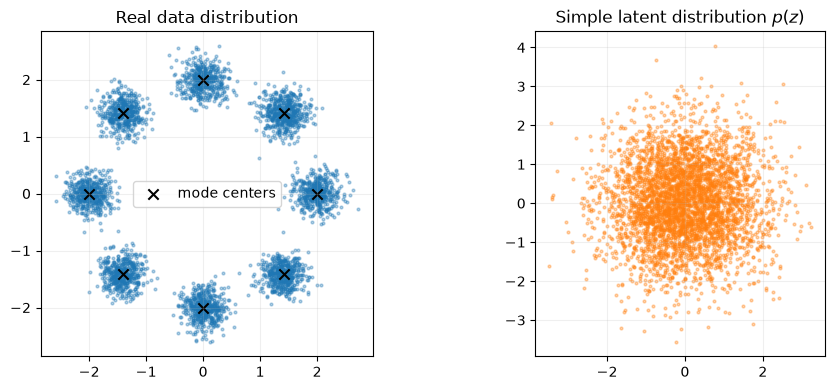

In [10]:
NUMBER_MODES = 8
DATA_RADIUS = 2.0
CLUSTER_STD = 0.2
LATENT_DIM = 2

angles = torch.linspace(0, 2 * torch.pi, NUMBER_MODES + 1)[:-1]
MODE_CENTERS = DATA_RADIUS * torch.stack((torch.cos(angles), torch.sin(angles)), dim=1)


def sample_real_data(batch_size, *, device=DEVICE):
    # select `batch_size` random mode indices.
    mode_indices = torch.randint(0, NUMBER_MODES, (batch_size,), device=device)
    # move the selected centers to `device` and add Gaussian cluster noise.
    centers = MODE_CENTERS.to(device)
    samples = (
        centers[mode_indices]
        + CLUSTER_STD * torch.randn(batch_size, LATENT_DIM, device=device)
    )
    return samples


def sample_latent(batch_size, *, device=DEVICE):
    return torch.randn(batch_size, LATENT_DIM, device=device)


real_examples = sample_real_data(4000)
latent_examples = sample_latent(4000)
assert real_examples.shape == latent_examples.shape == (4000, 2)
assert real_examples.device == DEVICE and latent_examples.device == DEVICE
assert 1.7 < real_examples.norm(dim=1).mean().item() < 2.3

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(*real_examples.detach().cpu().T, s=4, alpha=0.35)
axes[0].scatter(*MODE_CENTERS.T, color="black", marker="x", s=55, label="mode centers")
axes[0].set_title("Real data distribution")
axes[0].legend()
axes[1].scatter(*latent_examples.detach().cpu().T, s=4, alpha=0.35, color="tab:orange")
axes[1].set_title("Simple latent distribution $p(z)$")
for axis in axes:
    axis.set_aspect("equal")
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 2. Generator and discriminator

The generator transforms a latent vector into a two-dimensional generated point:

```text
(N, 2) latent vectors -> generator -> (N, 2) generated points
```

The discriminator receives either real or generated points and returns one **logit** per point:

```text
(N, 2) points -> discriminator -> (N, 1) real/fake logits
```

A positive discriminator logit suggests “real,” while a negative logit suggests “generated.” We keep logits rather than applying sigmoid inside the model because `binary_cross_entropy_with_logits` combines sigmoid and binary cross-entropy more stably.

### Exercise 2 — Complete both forward passes

In [11]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, hidden_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, latent_vectors):
        # transform the complete latent batch into generated 2D points.
        return self.network(latent_vectors)


class Discriminator(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, points):
        # return one real/fake logit for every point.
        return self.network(points)


torch.manual_seed(SEED)
shape_generator = Generator().to(DEVICE)
shape_discriminator = Discriminator().to(DEVICE)
generated_points = shape_generator(sample_latent(5))
generated_logits = shape_discriminator(generated_points)
assert generated_points.shape == (5, 2)
assert generated_logits.shape == (5, 1)
assert torch.isfinite(generated_points).all() and torch.isfinite(generated_logits).all()

## 3. The two training objectives

The discriminator solves an ordinary binary-classification problem. Real examples have target one and generated examples have target zero:

$$
\mathcal{L}_D=\mathrm{BCE}(D(x),1)+\mathrm{BCE}(D(G(z)),0).
$$

The generator wants the discriminator to classify its generated points as real. The commonly used non-saturating objective is

$$
\mathcal{L}_G=\mathrm{BCE}(D(G(z)),1).
$$

The target one does **not** claim that generated samples are real training examples. It encodes the generator's goal: produce points that the discriminator cannot distinguish from real data.

### Exercise 3 — Implement both losses

In [12]:
def discriminator_loss(real_logits, generated_logits):
    # classify real logits as 1 and generated logits as 0.
    real_loss = F.binary_cross_entropy_with_logits(real_logits, torch.ones_like(real_logits))
    generated_loss = F.binary_cross_entropy_with_logits(generated_logits, torch.zeros_like(generated_logits))
    return real_loss + generated_loss


def generator_loss(generated_logits):
    # make the discriminator classify generated examples as 1.
    return F.binary_cross_entropy_with_logits(generated_logits, torch.ones_like(generated_logits))


confident_real_logits = torch.tensor([[4.0], [3.0]])
confident_fake_logits = torch.tensor([[-4.0], [-3.0]])
wrong_real_logits = -confident_real_logits
wrong_fake_logits = -confident_fake_logits

good_discriminator_loss = discriminator_loss(confident_real_logits, confident_fake_logits)
bad_discriminator_loss = discriminator_loss(wrong_real_logits, wrong_fake_logits)
assert good_discriminator_loss.ndim == 0
assert good_discriminator_loss < bad_discriminator_loss
assert generator_loss(confident_real_logits) < generator_loss(confident_fake_logits)
print("good / bad discriminator loss:", good_discriminator_loss.item(), bad_discriminator_loss.item())

good / bad discriminator loss: 0.06673722714185715 7.066737174987793


## 4. Alternating updates and `detach`

GAN training alternates between two different optimization problems.

During a **discriminator update**, generated points are examples for the discriminator. The generator must not be updated, so we detach those points from the generator's computational graph:

```text
z -> G -> generated points --detach--> D -> discriminator loss
```

During a **generator update**, gradients must pass through the discriminator and continue into the generator:

```text
z -> G -> generated points -> D -> generator loss
       ^________________________ gradient reaches G
```

The discriminator optimizer is not stepped during the second update. Temporarily setting its parameters to `requires_grad_(False)` also avoids calculating discriminator parameter gradients that will not be used. Gradients with respect to the discriminator's **input** still flow through it to the generator.

### Exercise 4 — Implement one update for each network

In [17]:
def set_requires_grad(model, requires_grad):
    for parameter in model.parameters():
        parameter.requires_grad_(requires_grad)


def discriminator_step(generator, discriminator, optimizer, batch_size):
    set_requires_grad(discriminator, True)
    optimizer.zero_grad()

    # sample real points and latent vectors.
    sampled_real_points = sample_real_data(batch_size)
    latent_vectors = sample_latent(batch_size)
    # generate fake points and detach them from the generator graph.
    sampled_fake_points = generator(latent_vectors).detach()
    # calculate real/fake logits and the discriminator loss.
    real_logits = discriminator(sampled_real_points)
    fake_logits = discriminator(sampled_fake_points)
    loss = discriminator_loss(real_logits, fake_logits)
    # backpropagate and update the discriminator.
    loss.backward()
    optimizer.step()
    return loss.detach()


def generator_step(generator, discriminator, optimizer, batch_size):
    set_requires_grad(discriminator, False)
    optimizer.zero_grad()

    # sample latent vectors and generate fake points without detaching them.
    # pass them through the discriminator and calculate generator loss.
    latent_vectors = sample_latent(batch_size)
    sampled_fake_points = generator(latent_vectors)
    fake_logits = discriminator(sampled_fake_points)
    loss = generator_loss(fake_logits)
    # backpropagate through D into G, then update only the generator.
    loss.backward()
    optimizer.step()
    set_requires_grad(discriminator, True)
    return loss.detach()

The checks below verify the most important routing behavior: a discriminator step changes only discriminator parameters, while a generator step changes only generator parameters.

In [18]:
def parameters_changed(before, model):
    return any(not torch.equal(old, new.detach()) for old, new in zip(before, model.parameters()))


torch.manual_seed(SEED)
step_generator = Generator().to(DEVICE)
step_discriminator = Discriminator().to(DEVICE)
generator_optimizer = torch.optim.Adam(step_generator.parameters(), lr=1e-3)
discriminator_optimizer = torch.optim.Adam(step_discriminator.parameters(), lr=1e-3)

generator_before = [parameter.detach().clone() for parameter in step_generator.parameters()]
discriminator_before = [parameter.detach().clone() for parameter in step_discriminator.parameters()]
d_loss = discriminator_step(step_generator, step_discriminator, discriminator_optimizer, 64)
assert not parameters_changed(generator_before, step_generator)
assert parameters_changed(discriminator_before, step_discriminator)

generator_before = [parameter.detach().clone() for parameter in step_generator.parameters()]
discriminator_before = [parameter.detach().clone() for parameter in step_discriminator.parameters()]
g_loss = generator_step(step_generator, step_discriminator, generator_optimizer, 64)
assert parameters_changed(generator_before, step_generator)
assert not parameters_changed(discriminator_before, step_discriminator)
assert torch.isfinite(d_loss) and torch.isfinite(g_loss)
print("one-step losses:", d_loss.item(), g_loss.item())

one-step losses: 1.382493495941162 0.7620619535446167


## 5. Train the GAN

There is no fixed target point for each latent vector. The generator improves only through the discriminator's changing feedback. For that reason, GAN loss curves are less straightforward than supervised-learning curves: a discriminator loss can increase because the generator improved, and a generator loss can increase because the discriminator improved.

We will store generated samples at several checkpoints. Their geometry is more informative than either loss alone.

### Exercise 5 — Complete the alternating training loop

In [19]:
@torch.no_grad()
def generate_points(generator, latent_vectors):
    generator.eval()
    return generator(latent_vectors).detach().cpu()


def train_gan(
    *,
    steps=3000,
    batch_size=256,
    generator_learning_rate=1e-3,
    discriminator_learning_rate=1e-3,
    snapshot_steps=(0, 250, 1000, 3000),
    seed=SEED,
):
    torch.manual_seed(seed)
    generator = Generator().to(DEVICE)
    discriminator = Discriminator().to(DEVICE)
    generator_optimizer = torch.optim.Adam(generator.parameters(), lr=generator_learning_rate, betas=(0.5, 0.999))
    discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=discriminator_learning_rate, betas=(0.5, 0.999))
    fixed_latent = sample_latent(3000)
    history = {"generator": [], "discriminator": []}
    snapshots = {0: generate_points(generator, fixed_latent)}

    generator.train()
    discriminator.train()
    for step in range(1, steps + 1):
        # perform one discriminator step and one generator step.
        d_loss = discriminator_step(generator, discriminator, discriminator_optimizer, batch_size)
        g_loss = generator_step(generator, discriminator, generator_optimizer, batch_size)
        # append ordinary Python loss values to the two history lists.
        history["generator"].append(g_loss.item())
        history["discriminator"].append(d_loss.item())

        if step in snapshot_steps:
            snapshots[step] = generate_points(generator, fixed_latent)
            generator.train()

    return generator, discriminator, history, snapshots


generator, discriminator, history, snapshots = train_gan()
assert len(history["generator"]) == len(history["discriminator"]) == 3000
assert set(snapshots) == {0, 250, 1000, 3000}
assert all(points.shape == (3000, 2) for points in snapshots.values())

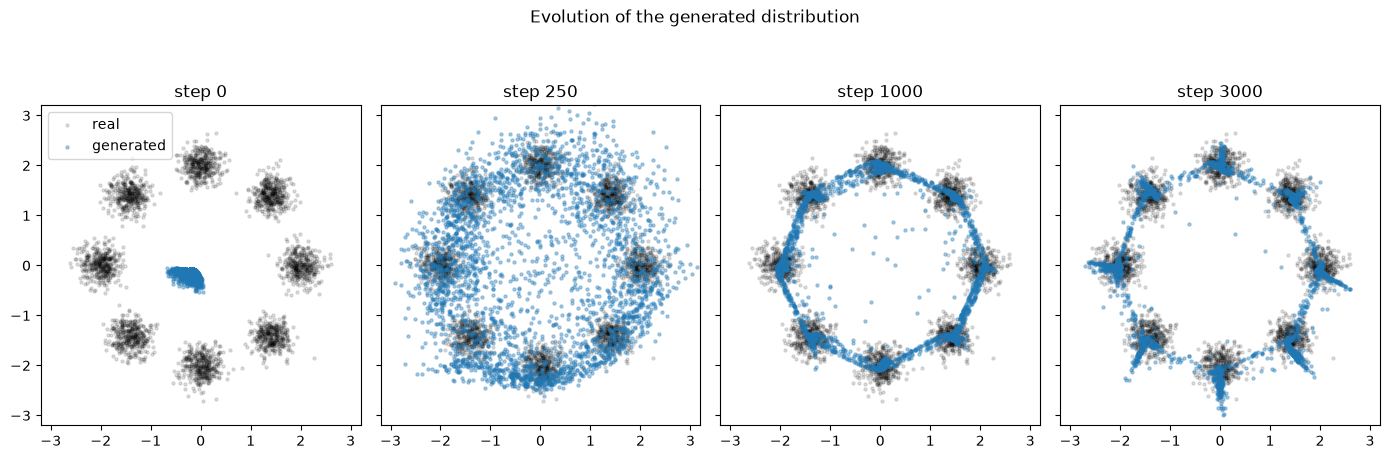

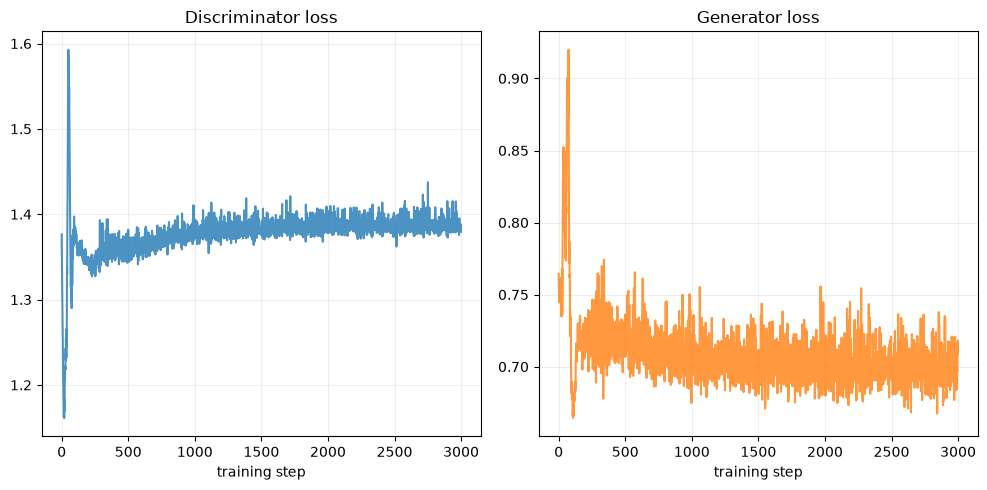

In [26]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(14, 5), sharex=True, sharey=True)
real_reference = sample_real_data(3000, device=torch.device("cpu"))
for axis, (step, generated) in zip(axes, snapshots.items()):
    axis.scatter(*real_reference.T, s=5, alpha=0.12, color="black", label="real")
    axis.scatter(*generated.T, s=5, alpha=0.35, color="tab:blue", label="generated")
    axis.set_title(f"step {step}")
    axis.set_aspect("equal")
    axis.set_xlim(-3.2, 3.2)
    axis.set_ylim(-3.2, 3.2)
axes[0].legend(loc="upper left")
plt.suptitle("Evolution of the generated distribution")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].plot(history["discriminator"], alpha=0.8)
axes[0].set_title("Discriminator loss")
axes[1].plot(history["generator"], color="tab:orange", alpha=0.8)
axes[1].set_title("Generator loss")
for axis in axes:
    axis.set_xlabel("training step")
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Quantify mode coverage

Visual inspection is useful, but we can also assign every generated point to its nearest real mode center. We call a mode **covered** when it receives at least a small fraction of generated samples.

This is a diagnostic designed for our known toy distribution, not a general-purpose GAN evaluation metric. Real image distributions do not provide a short list of exact mode centers.

### Exercise 6 — Assign generated points to modes

covered modes: 8/8
mean distance to nearest mode: 0.225


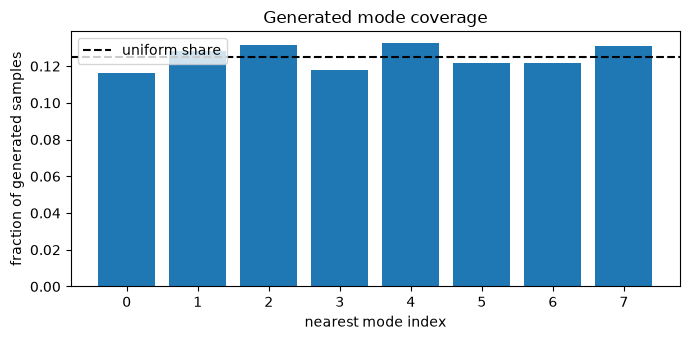

In [28]:
def mode_statistics(points, centers=MODE_CENTERS, minimum_fraction=0.02):
    points = points.detach().cpu()
    centers = centers.detach().cpu()
    # calculate every point-to-center Euclidean distance with shape (N, number_modes).
    distances = torch.cdist(points, centers)
    # assign each point to the nearest center and count assignments.
    assignments = distances.argmin(dim=1)
    counts = torch.bincount(assignments, minlength=NUMBER_MODES)
    fractions = counts.float() / points.shape[0]
    covered = int((fractions >= minimum_fraction).sum().item())
    mean_nearest_distance = distances.min(dim=1).values.mean().item()
    return counts, fractions, covered, mean_nearest_distance


final_points = snapshots[max(snapshots)]
counts, fractions, covered, mean_distance = mode_statistics(final_points)
assert counts.shape == fractions.shape == (NUMBER_MODES,)
assert counts.sum().item() == len(final_points)
assert 0 <= covered <= NUMBER_MODES
print(f"covered modes: {covered}/{NUMBER_MODES}")
print(f"mean distance to nearest mode: {mean_distance:.3f}")

plt.figure(figsize=(7, 3.5))
plt.bar(np.arange(NUMBER_MODES), fractions.numpy())
plt.axhline(1 / NUMBER_MODES, color="black", linestyle="--", label="uniform share")
plt.xlabel("nearest mode index")
plt.ylabel("fraction of generated samples")
plt.title("Generated mode coverage")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Latent interpolation

The generator is a continuous function. Moving gradually between latent vectors therefore produces a continuous path in data space:

$$
z(t)=(1-t)z_0+t z_1,
\qquad
x(t)=G(z(t)).
$$

Continuity does not guarantee that every intermediate generated point lies in a high-density data region. The visualization lets us inspect what path this particular generator learned.

### Exercise 7 — Generate and visualize an interpolation path

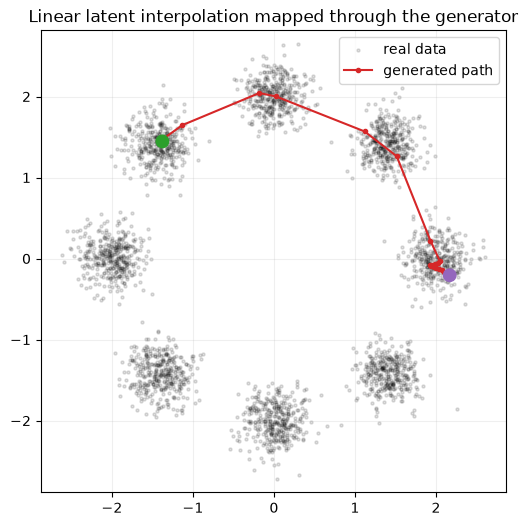

In [30]:
torch.manual_seed(SEED + 1)
endpoints = sample_latent(2)
interpolation_weights = torch.linspace(0, 1, 25, device=DEVICE).unsqueeze(1)
# interpolate from endpoints[0] to endpoints[1] with shape (25, 2).
latent_path = endpoints[0] * (1 - interpolation_weights) + endpoints[1] * interpolation_weights
with torch.no_grad():
    generated_path = generator(latent_path).cpu()

assert latent_path.shape == generated_path.shape == (25, 2)

plt.figure(figsize=(6, 6))
plt.scatter(*real_reference.T, s=5, alpha=0.12, color="black", label="real data")
plt.plot(*generated_path.T, marker="o", markersize=3, color="tab:red", label="generated path")
plt.scatter(*generated_path[[0, -1]].T, s=80, color=["tab:green", "tab:purple"], zorder=3)
plt.axis("equal")
plt.title("Linear latent interpolation mapped through the generator")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Why use the non-saturating generator objective?

Let $p=D(G(z))$ be the discriminator's estimated probability that a generated sample is real. The original minimax generator term minimizes

$$
\log(1-p),
$$

whereas the non-saturating alternative minimizes

$$
-\log(p).
$$

At the beginning of training, $p$ is often close to zero because the discriminator easily detects poor generated samples. The non-saturating loss produces a much stronger gradient with respect to the generator's discriminator logit in this region.

### Exercise 8 — Compare loss and gradient magnitudes

Use logits from $-8$ to $8$. Calculate both generator losses and use `torch.autograd.grad` to obtain their gradients with respect to the logits.

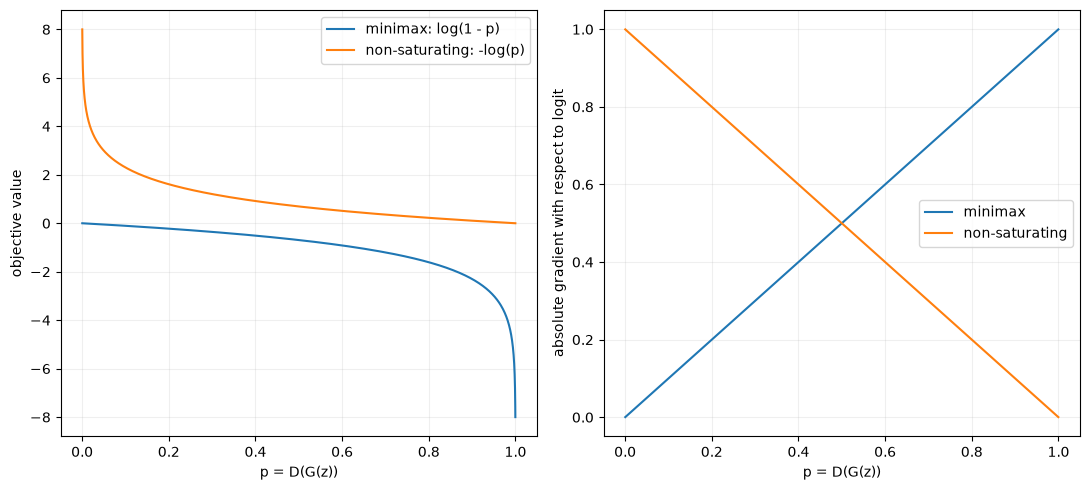

In [35]:
logits = torch.linspace(-8, 8, 400, requires_grad=True)
probabilities = torch.sigmoid(logits)
#  calculate element-wise minimax log(1 - p) and non-saturating -log(p) losses.
# Prefer stable expressions based on logits rather than manually taking logs of probabilities.
minimax_values = -F.softplus(logits)
non_saturating_values = F.softplus(-logits)
## unstable for extreme logits
# minimax_values = torch.log1p(-probabilities)
# non_saturating_values = -torch.log(probabilities)
# calculate each loss gradient with respect to `logits`.
minimax_gradients = torch.autograd.grad(minimax_values.sum(), logits, create_graph=True)[0]
non_saturating_gradients = torch.autograd.grad(non_saturating_values.sum(), logits, create_graph=True)[0]

assert minimax_values.shape == non_saturating_values.shape == logits.shape
assert minimax_gradients.shape == non_saturating_gradients.shape == logits.shape

probabilities_numpy = probabilities.detach().numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].plot(probabilities_numpy, minimax_values.detach().numpy(), label="minimax: log(1 - p)")
axes[0].plot(probabilities_numpy, non_saturating_values.detach().numpy(), label="non-saturating: -log(p)")
axes[0].set_ylabel("objective value")
axes[1].plot(probabilities_numpy, minimax_gradients.abs().detach().numpy(), label="minimax")
axes[1].plot(probabilities_numpy, non_saturating_gradients.abs().detach().numpy(), label="non-saturating")
axes[1].set_ylabel("absolute gradient with respect to logit")
for axis in axes:
    axis.set_xlabel("p = D(G(z))")
    axis.grid(alpha=0.2)
    axis.legend()
plt.tight_layout()
plt.show()

## 9. Optional: a deliberately unbalanced experiment

A GAN contains two learners whose relative strength matters. If the discriminator learns much faster, it may reject generated points confidently before the generator has learned a useful mapping. If the generator dominates, it may exploit temporary weaknesses in the discriminator.

Run the experiment below after the baseline. The exact outcome is stochastic; look for missing modes, uneven mode frequencies, oscillation, or poorer proximity to the real clusters rather than expecting one predetermined failure.

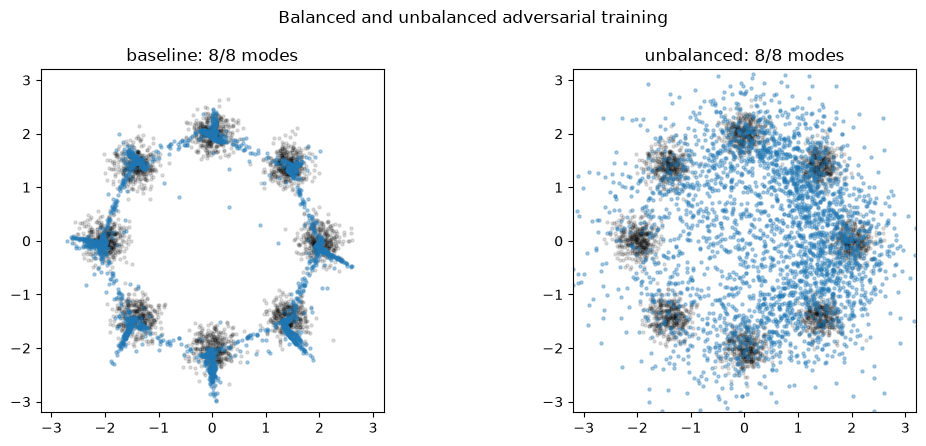

baseline mean nearest-mode distance:   0.225
unbalanced mean nearest-mode distance: 0.704


In [37]:
unbalanced_generator, _, unbalanced_history, unbalanced_snapshots = train_gan(
    steps=4000,
    generator_learning_rate=2e-5,
    discriminator_learning_rate=3e-3,
    seed=SEED + 10,
)
unbalanced_points = unbalanced_snapshots[3000]
_, unbalanced_fractions, unbalanced_covered, unbalanced_distance = mode_statistics(unbalanced_points)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, points, title in (
    (axes[0], final_points, f"baseline: {covered}/8 modes"),
    (axes[1], unbalanced_points, f"unbalanced: {unbalanced_covered}/8 modes"),
):
    axis.scatter(*real_reference.T, s=5, alpha=0.12, color="black")
    axis.scatter(*points.T, s=5, alpha=0.35)
    axis.set_title(title)
    axis.set_aspect("equal")
    axis.set_xlim(-3.2, 3.2)
    axis.set_ylim(-3.2, 3.2)
plt.suptitle("Balanced and unbalanced adversarial training")
plt.tight_layout()
plt.show()

print(f"baseline mean nearest-mode distance:   {mean_distance:.3f}")
print(f"unbalanced mean nearest-mode distance: {unbalanced_distance:.3f}")

## Reflection

Answer briefly after running the experiments.

1. Why does the generator receive random latent vectors rather than examples from the real dataset?

   **Answer:** Random latent vectors provide a simple source of variation from which we can sample. The generator does not directly receive real examples; the discriminator sees real data and provides feedback that guides the generator toward the real data distribution.

2. Why must generated samples be detached during the discriminator update but not during the generator update?

   **Answer:** During the discriminator update, detach stops discriminator-loss gradients from flowing into and accumulating in the generator. During the generator update, that path must remain connected so the discriminator’s feedback can update the generator.

3. Did the baseline generator cover all eight modes? What do the mode histogram and nearest-mode distance reveal that a loss curve does not?

   **Answer:** Yes, the baseline covered all eight modes, although their generated frequencies were slightly imbalanced. The histogram measures coverage and balance, while the mean nearest-mode distance of 0.225 measures how close generated points are to real clusters. The loss curves do not directly reveal either property.

4. Why can GAN losses oscillate or become harder to interpret even when generated samples improve?

   **Answer:** Both networks change simultaneously, so each network trains against a moving opponent rather than a fixed objective. When one improves, the other network’s loss can increase, meaning oscillating losses do not necessarily imply worsening samples.

5. What happened in the unbalanced experiment, and why should we avoid assuming that the same failure occurs for every random seed?

   **Answer:** The slower generator still covered all eight modes, but its samples were less balanced and much farther from the real clusters: the mean nearest-mode distance increased from 0.225 to 0.704. GAN optimization is stochastic and sensitive to initialization and sampled batches, so another seed may produce a different failure pattern.

6. Why does the non-saturating objective provide a stronger generator learning signal when the discriminator confidently rejects generated samples?

   **Answer:** When the discriminator confidently rejects generated samples, $D(G(z))$ is near zero. The original minimax generator gradient then nearly vanishes, whereas the non-saturating loss has a large gradient with respect to the discriminator logit and gives the generator a useful learning signal.